<a href="https://colab.research.google.com/github/kassahun-12/Regression-Baseline/blob/main/DS_A3_%7C_Regression_Baseline_and_Diagnostics_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**DS-A3 | Regression Baseline and Diagnostics **

#Name: Kassahun Azezew Ayidagn
#**ID: 2026A8002209001**
**GitHub link: https://github.com/kassahun-12/Regression-Baseline**

**Environment and reproducibility**

In [1]:
import os
import sys
import platform
import random
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Python:", sys.version)
print("Platform:", platform.platform())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Random seed:", SEED)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
NumPy: 2.1.3
Pandas: 2.2.3
Scikit-learn: 1.6.1
Random seed: 42


**Upload and extract the datasets**

In [6]:
from google.colab import files
from pathlib import Path
import zipfile

uploaded = files.upload()

DATA_DIR = Path("/content/fingerprint_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

for filename in uploaded:
    if not filename.lower().endswith(".zip"):
        print("Skipping non-ZIP file:", filename)
        continue

    with zipfile.ZipFile(filename, "r") as archive:
        for member in archive.infolist():
            target = (DATA_DIR / member.filename).resolve()

            if not target.is_relative_to(DATA_DIR.resolve()):
                raise ValueError("Unsafe archive path detected.")

        archive.extractall(DATA_DIR / Path(filename).stem)

print("Extraction complete.")

for path in sorted(DATA_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(DATA_DIR))

Saving DB1_B.zip to DB1_B (1).zip
Saving DB2_B.zip to DB2_B (1).zip
Extraction complete.
DB1_B (1)/101_1.tif
DB1_B (1)/101_2.tif
DB1_B (1)/101_3.tif
DB1_B (1)/101_4.tif
DB1_B (1)/101_5.tif
DB1_B (1)/101_6.tif
DB1_B (1)/101_7.tif
DB1_B (1)/101_8.tif
DB1_B (1)/102_1.tif
DB1_B (1)/102_2.tif
DB1_B (1)/102_3.tif
DB1_B (1)/102_4.tif
DB1_B (1)/102_5.tif
DB1_B (1)/102_6.tif
DB1_B (1)/102_7.tif
DB1_B (1)/102_8.tif
DB1_B (1)/103_1.tif
DB1_B (1)/103_2.tif
DB1_B (1)/103_3.tif
DB1_B (1)/103_4.tif
DB1_B (1)/103_5.tif
DB1_B (1)/103_6.tif
DB1_B (1)/103_7.tif
DB1_B (1)/103_8.tif
DB1_B (1)/104_1.tif
DB1_B (1)/104_2.tif
DB1_B (1)/104_3.tif
DB1_B (1)/104_4.tif
DB1_B (1)/104_5.tif
DB1_B (1)/104_6.tif
DB1_B (1)/104_7.tif
DB1_B (1)/104_8.tif
DB1_B (1)/105_1.tif
DB1_B (1)/105_2.tif
DB1_B (1)/105_3.tif
DB1_B (1)/105_4.tif
DB1_B (1)/105_5.tif
DB1_B (1)/105_6.tif
DB1_B (1)/105_7.tif
DB1_B (1)/105_8.tif
DB1_B (1)/106_1.tif
DB1_B (1)/106_2.tif
DB1_B (1)/106_3.tif
DB1_B (1)/106_4.tif
DB1_B (1)/106_5.tif
DB1_B (1)/1

**Audit filenames and group impressions**

In [7]:
import pandas as pd
from collections import Counter

records = []

for dataset_dir in sorted(DATA_DIR.iterdir()):
    if not dataset_dir.is_dir():
        continue

    for path in sorted(dataset_dir.rglob("*.tif")):
        # Expected filename format: 101_1.tif
        parts = path.stem.split("_")

        if len(parts) != 2:
            print("Unexpected filename:", path.name)
            continue

        finger_id, impression_id = parts

        records.append({
            "dataset": dataset_dir.name,
            "file": str(path),
            "finger_id": finger_id,
            "impression_id": impression_id,
        })

manifest = pd.DataFrame(records)

print("Total images:", len(manifest))
print("Images per dataset:")
display(manifest.groupby("dataset").size().to_frame("image_count"))

print("Impressions per finger and dataset:")
display(
    manifest.groupby(["dataset", "finger_id"])
    .size()
    .unstack(fill_value=0)
)

print("Duplicate dataset/finger/impression records:")
display(
    manifest[
        manifest.duplicated(
            ["dataset", "finger_id", "impression_id"],
            keep=False
        )
    ]
)

Total images: 160
Images per dataset:


,image_count
dataset,
DB1_B (1),80
DB2_B (1),80


Impressions per finger and dataset:


finger_id,101,102,103,104,105,106,107,108,109,110
dataset,,,,,,,,,,
DB1_B (1),8,8,8,8,8,8,8,8,8,8
DB2_B (1),8,8,8,8,8,8,8,8,8,8


Duplicate dataset/finger/impression records:


,dataset,file,finger_id,impression_id


**Display sample fingerprint images**

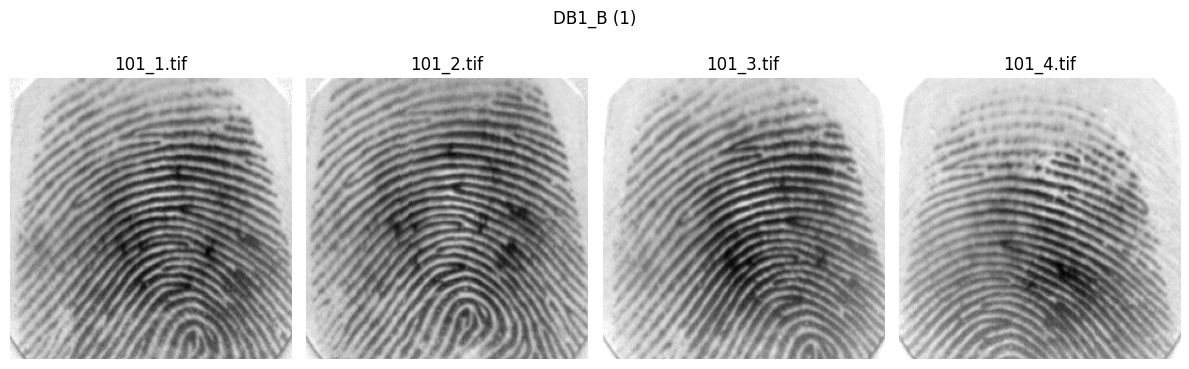

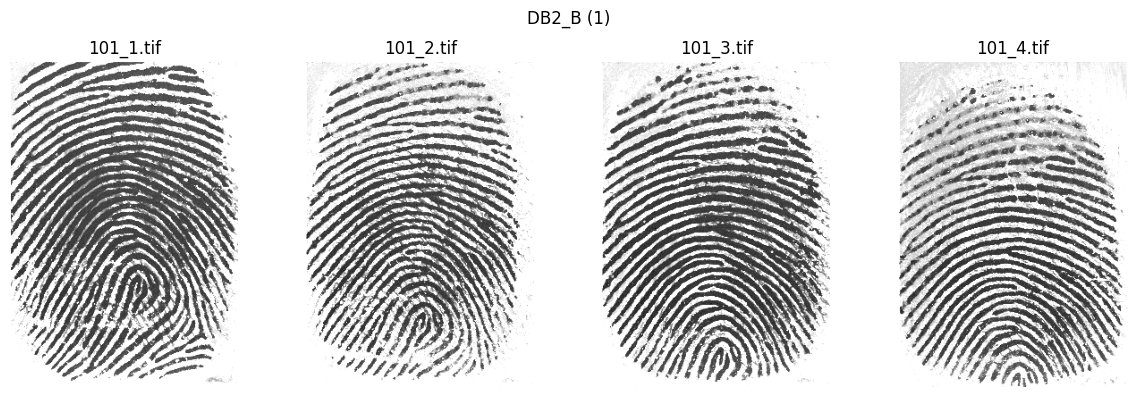

In [8]:
from PIL import Image
import matplotlib.pyplot as plt

for dataset_dir in sorted(DATA_DIR.iterdir()):
    if not dataset_dir.is_dir():
        continue

    image_paths = sorted(dataset_dir.rglob("*.tif"))[:4]

    if not image_paths:
        continue

    fig, axes = plt.subplots(1, len(image_paths), figsize=(12, 4))
    if len(image_paths) == 1:
        axes = [axes]

    for ax, path in zip(axes, image_paths):
        with Image.open(path) as image:
            ax.imshow(image, cmap="gray")
        ax.set_title(path.name)
        ax.axis("off")

    fig.suptitle(dataset_dir.name)
    plt.tight_layout()
    plt.show()

**audit the identities before splitting**

In [9]:
# DS-A3 — Identity and image audit

from pathlib import Path
import pandas as pd

DATA_DIR = Path("/content/fingerprint_data")

rows = []

for dataset_dir in sorted(DATA_DIR.iterdir()):
    if not dataset_dir.is_dir():
        continue

    for path in sorted(dataset_dir.rglob("*")):
        if path.suffix.lower() not in {".tif", ".tiff"}:
            continue

        parts = path.stem.split("_")

        if len(parts) != 2:
            print("Review filename:", path.name)
            continue

        finger_id, impression_id = parts

        rows.append({
            "dataset": dataset_dir.name,
            "finger_id": finger_id,
            "impression_id": impression_id,
            "path": str(path),
        })

manifest = pd.DataFrame(rows)

if manifest.empty:
    raise ValueError("No TIFF images found. Check the extracted paths.")

manifest["identity_group"] = (
    manifest["dataset"].astype(str)
    + "::"
    + manifest["finger_id"].astype(str)
)

print("Image count:", len(manifest))
print("Unique identity groups:", manifest["identity_group"].nunique())

print("\nImages per identity:")
display(
    manifest.groupby(["dataset", "finger_id"])
    .size()
    .rename("n_images")
    .reset_index()
)

print("\nDuplicate paths:", manifest["path"].duplicated().sum())
print(
    "Duplicate identity/impression records:",
    manifest.duplicated(
        ["dataset", "finger_id", "impression_id"]
    ).sum()
)

Image count: 160
Unique identity groups: 20

Images per identity:


,dataset,finger_id,n_images
0,DB1_B (1),101,8
1,DB1_B (1),102,8
2,DB1_B (1),103,8
3,DB1_B (1),104,8
4,DB1_B (1),105,8
5,DB1_B (1),106,8
6,DB1_B (1),107,8
7,DB1_B (1),108,8
8,DB1_B (1),109,8
9,DB1_B (1),110,8



Duplicate paths: 0
Duplicate identity/impression records: 0


**create and save the identity split**

In [10]:
# DS-A3 — Freeze identity partitions

from sklearn.model_selection import train_test_split
from pathlib import Path
import json

SEED = 42
OUTPUT_DIR = Path("/content/ds_a3_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

identity_groups = sorted(manifest["identity_group"].unique())

# Reserve 30% for validation and test.
train_ids, remaining_ids = train_test_split(
    identity_groups,
    test_size=0.30,
    random_state=SEED
)

# Split the reserved identities equally.
validation_ids, test_ids = train_test_split(
    remaining_ids,
    test_size=0.50,
    random_state=SEED
)

partitions = {
    "train": sorted(train_ids),
    "validation": sorted(validation_ids),
    "test": sorted(test_ids),
}

# Audit disjointness before saving.
assert set(partitions["train"]).isdisjoint(partitions["validation"])
assert set(partitions["train"]).isdisjoint(partitions["test"])
assert set(partitions["validation"]).isdisjoint(partitions["test"])

assert set().union(*map(set, partitions.values())) == set(identity_groups)

split_path = OUTPUT_DIR / "identity_split.json"
split_path.write_text(json.dumps({
    "seed": SEED,
    "strategy": "identity-level split",
    "partitions": partitions,
}, indent=2))

for name, identities in partitions.items():
    print(f"{name}: {len(identities)} identities")

print("Saved split:", split_path)

train: 14 identities
validation: 3 identities
test: 3 identities
Saved split: /content/ds_a3_results/identity_split.json


**Generate pairs within each partition**

In [11]:
# DS-A3 — Pair construction
# Pairs are constructed separately within each identity partition.

import itertools
import pandas as pd

def make_pairs(manifest, identity_ids):
    subset = manifest[
        manifest["identity_group"].isin(identity_ids)
    ].copy()

    pairs = []

    # Genuine pairs: different impressions of the same identity.
    for identity, group in subset.groupby("identity_group"):
        records = group.to_dict("records")

        for a, b in itertools.combinations(records, 2):
            if a["path"] != b["path"]:
                pairs.append({
                    "image_a": a["path"],
                    "image_b": b["path"],
                    "identity_a": a["identity_group"],
                    "identity_b": b["identity_group"],
                    "label": 1,
                })

    # Impostor pairs: different identities within the partition.
    identity_groups = [
        group for _, group in subset.groupby("identity_group")
    ]

    for group_a, group_b in itertools.combinations(identity_groups, 2):
        # Pair each image from one identity with an image from the other.
        for a in group_a.to_dict("records"):
            for b in group_b.to_dict("records"):
                pairs.append({
                    "image_a": a["path"],
                    "image_b": b["path"],
                    "identity_a": a["identity_group"],
                    "identity_b": b["identity_group"],
                    "label": 0,
                })

    return pd.DataFrame(pairs)


pair_sets = {}

for split_name, identity_ids in partitions.items():
    pair_sets[split_name] = make_pairs(manifest, identity_ids)

    print(f"\n{split_name.upper()}")
    print("Number of pairs:", len(pair_sets[split_name]))
    print(pair_sets[split_name]["label"].value_counts().sort_index())

    assert (
        pair_sets[split_name]["identity_a"]
        .isin(identity_ids).all()
    )
    assert (
        pair_sets[split_name]["identity_b"]
        .isin(identity_ids).all()
    )

print("\nPair construction complete.")


TRAIN
Number of pairs: 6216
label
0    5824
1     392
Name: count, dtype: int64

VALIDATION
Number of pairs: 276
label
0    192
1     84
Name: count, dtype: int64

TEST
Number of pairs: 276
label
0    192
1     84
Name: count, dtype: int64

Pair construction complete.


**Verify the pair labels and split boundaries**

In [12]:
for split_name, pairs in pair_sets.items():
    genuine = pairs[pairs["label"] == 1]
    impostor = pairs[pairs["label"] == 0]

    assert (genuine["identity_a"] == genuine["identity_b"]).all()
    assert (impostor["identity_a"] != impostor["identity_b"]).all()

    print(
        split_name,
        "| genuine:", len(genuine),
        "| impostor:", len(impostor),
        "| label checks passed"
    )

# Save the generated pair manifests for reproducibility.
for split_name, pairs in pair_sets.items():
    pairs.to_csv(
        OUTPUT_DIR / f"{split_name}_pairs.csv",
        index=False
    )

print("Pair manifests saved to:", OUTPUT_DIR)

train | genuine: 392 | impostor: 5824 | label checks passed
validation | genuine: 84 | impostor: 192 | label checks passed
test | genuine: 84 | impostor: 192 | label checks passed
Pair manifests saved to: /content/ds_a3_results


**Extract interpretable similarity features**

In [13]:
# Cell 8: Extract similarity features from fingerprint pairs

import numpy as np
import pandas as pd
from PIL import Image
from skimage.metrics import structural_similarity
from pathlib import Path
from tqdm.auto import tqdm

IMAGE_SIZE = (128, 128)

def load_fingerprint(path):
    """Load a fingerprint as a normalized grayscale array."""
    with Image.open(path) as img:
        img = img.convert("L")
        img = img.resize(IMAGE_SIZE, Image.Resampling.LANCZOS)
        arr = np.asarray(img, dtype=np.float32) / 255.0
    return arr

def extract_pair_features(path_a, path_b):
    """Calculate simple, interpretable image similarity features."""
    a = load_fingerprint(path_a)
    b = load_fingerprint(path_b)

    # Mean absolute pixel difference
    mean_abs_diff = float(np.mean(np.abs(a - b)))

    # Pearson correlation of pixel intensities
    std_a, std_b = np.std(a), np.std(b)
    if std_a < 1e-8 or std_b < 1e-8:
        correlation = 0.0
    else:
        correlation = float(np.corrcoef(a.ravel(), b.ravel())[0, 1])

    # Structural similarity
    ssim = float(
        structural_similarity(a, b, data_range=1.0)
    )

    return {
        "mean_abs_diff": mean_abs_diff,
        "pixel_correlation": correlation,
        "ssim": ssim,
    }

feature_sets = {}

for split_name, pairs in pair_sets.items():
    cache = {}

    def get_image(path):
        if path not in cache:
            cache[path] = load_fingerprint(path)
        return cache[path]

    rows = []

    for row in tqdm(
        pairs.itertuples(index=False),
        total=len(pairs),
        desc=f"Features: {split_name}"
    ):
        a = get_image(row.image_a)
        b = get_image(row.image_b)

        std_a, std_b = np.std(a), np.std(b)

        corr = (
            float(np.corrcoef(a.ravel(), b.ravel())[0, 1])
            if std_a >= 1e-8 and std_b >= 1e-8
            else 0.0
        )

        rows.append({
            "mean_abs_diff": float(np.mean(np.abs(a - b))),
            "pixel_correlation": corr,
            "ssim": float(
                structural_similarity(a, b, data_range=1.0)
            ),
            "label": int(row.label),
            "identity_a": row.identity_a,
            "identity_b": row.identity_b,
            "image_a": row.image_a,
            "image_b": row.image_b,
        })

    feature_sets[split_name] = pd.DataFrame(rows)

    output_path = OUTPUT_DIR / f"{split_name}_features.csv"
    feature_sets[split_name].to_csv(output_path, index=False)

    print(f"\n{split_name}:")
    print("Feature rows:", len(feature_sets[split_name]))
    print("Saved:", output_path)
    display(feature_sets[split_name].head())

Features: train:   0%|          | 0/6216 [00:00<?, ?it/s]


train:
Feature rows: 6216
Saved: /content/ds_a3_results/train_features.csv


,mean_abs_diff,pixel_correlation,ssim,label,identity_a,identity_b,image_a,image_b
0,0.100880,0.453002,0.177228,1,DB1_B (1)::103,DB1_B (1)::103,/content/fingerprint_data/DB1_B (1)/103_1.tif,/content/fingerprint_data/DB1_B (1)/103_2.tif
1,0.075362,0.479042,0.199734,1,DB1_B (1)::103,DB1_B (1)::103,/content/fingerprint_data/DB1_B (1)/103_1.tif,/content/fingerprint_data/DB1_B (1)/103_3.tif
2,0.068697,0.489473,0.225245,1,DB1_B (1)::103,DB1_B (1)::103,/content/fingerprint_data/DB1_B (1)/103_1.tif,/content/fingerprint_data/DB1_B (1)/103_4.tif
3,0.084010,0.429103,0.152609,1,DB1_B (1)::103,DB1_B (1)::103,/content/fingerprint_data/DB1_B (1)/103_1.tif,/content/fingerprint_data/DB1_B (1)/103_5.tif
4,0.082013,0.432905,0.156390,1,DB1_B (1)::103,DB1_B (1)::103,/content/fingerprint_data/DB1_B (1)/103_1.tif,/content/fingerprint_data/DB1_B (1)/103_6.tif


Features: validation:   0%|          | 0/276 [00:00<?, ?it/s]


validation:
Feature rows: 276
Saved: /content/ds_a3_results/validation_features.csv


,mean_abs_diff,pixel_correlation,ssim,label,identity_a,identity_b,image_a,image_b
0,0.118548,0.344535,0.126674,1,DB1_B (1)::102,DB1_B (1)::102,/content/fingerprint_data/DB1_B (1)/102_1.tif,/content/fingerprint_data/DB1_B (1)/102_2.tif
1,0.121940,0.381351,0.189567,1,DB1_B (1)::102,DB1_B (1)::102,/content/fingerprint_data/DB1_B (1)/102_1.tif,/content/fingerprint_data/DB1_B (1)/102_3.tif
2,0.103826,0.487551,0.175717,1,DB1_B (1)::102,DB1_B (1)::102,/content/fingerprint_data/DB1_B (1)/102_1.tif,/content/fingerprint_data/DB1_B (1)/102_4.tif
3,0.094852,0.571017,0.230353,1,DB1_B (1)::102,DB1_B (1)::102,/content/fingerprint_data/DB1_B (1)/102_1.tif,/content/fingerprint_data/DB1_B (1)/102_5.tif
4,0.123422,0.180117,0.125296,1,DB1_B (1)::102,DB1_B (1)::102,/content/fingerprint_data/DB1_B (1)/102_1.tif,/content/fingerprint_data/DB1_B (1)/102_6.tif


Features: test:   0%|          | 0/276 [00:00<?, ?it/s]


test:
Feature rows: 276
Saved: /content/ds_a3_results/test_features.csv


,mean_abs_diff,pixel_correlation,ssim,label,identity_a,identity_b,image_a,image_b
0,0.093218,0.611070,0.211486,1,DB1_B (1)::101,DB1_B (1)::101,/content/fingerprint_data/DB1_B (1)/101_1.tif,/content/fingerprint_data/DB1_B (1)/101_2.tif
1,0.081538,0.700643,0.200380,1,DB1_B (1)::101,DB1_B (1)::101,/content/fingerprint_data/DB1_B (1)/101_1.tif,/content/fingerprint_data/DB1_B (1)/101_3.tif
2,0.104701,0.641212,0.209651,1,DB1_B (1)::101,DB1_B (1)::101,/content/fingerprint_data/DB1_B (1)/101_1.tif,/content/fingerprint_data/DB1_B (1)/101_4.tif
3,0.099517,0.522197,0.103227,1,DB1_B (1)::101,DB1_B (1)::101,/content/fingerprint_data/DB1_B (1)/101_1.tif,/content/fingerprint_data/DB1_B (1)/101_5.tif
4,0.100862,0.477968,0.146902,1,DB1_B (1)::101,DB1_B (1)::101,/content/fingerprint_data/DB1_B (1)/101_1.tif,/content/fingerprint_data/DB1_B (1)/101_6.tif


**Inspect feature distributions**

Training class counts:


,count
label,
Impostor,5824
Genuine,392


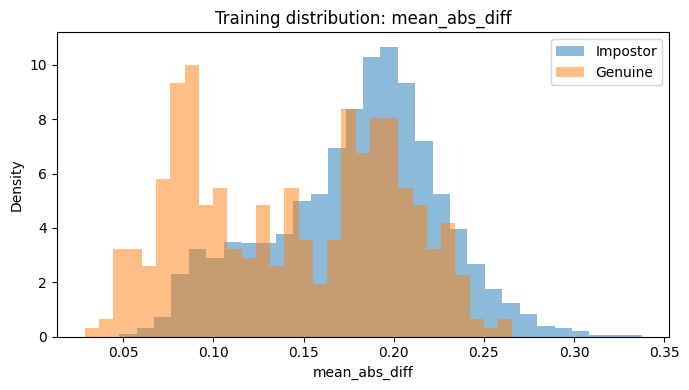

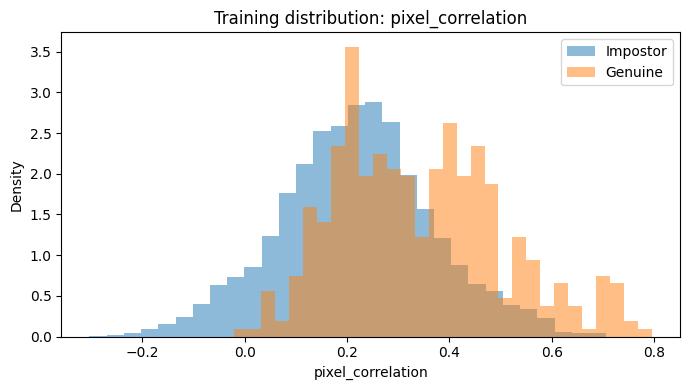

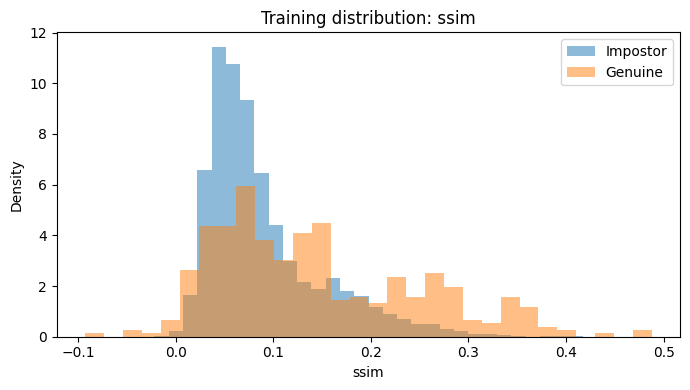

In [14]:
# Cell 9: Explore training feature distributions

import matplotlib.pyplot as plt

train_features = feature_sets["train"]

feature_columns = [
    "mean_abs_diff",
    "pixel_correlation",
    "ssim",
]

print("Training class counts:")
display(
    train_features["label"]
    .value_counts()
    .rename(index={0: "Impostor", 1: "Genuine"})
    .to_frame("count")
)

for feature in feature_columns:
    plt.figure(figsize=(7, 4))

    for label, name in [(0, "Impostor"), (1, "Genuine")]:
        values = train_features.loc[
            train_features["label"] == label, feature
        ]
        plt.hist(
            values,
            bins=30,
            alpha=0.5,
            density=True,
            label=name
        )

    plt.xlabel(feature)
    plt.ylabel("Density")
    plt.title(f"Training distribution: {feature}")
    plt.legend()
    plt.tight_layout()
    plt.show()

**Establish a naive baseline**

In [15]:
# Cell 10: Majority-class baseline

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
)

y_train = train_features["label"].to_numpy()
y_test = feature_sets["test"]["label"].to_numpy()

majority_class = int(
    pd.Series(y_train).value_counts().idxmax()
)

baseline_predictions = np.full(
    shape=len(y_test),
    fill_value=majority_class,
    dtype=int
)

print("Majority class selected:", majority_class)
print("Test accuracy:", accuracy_score(
    y_test, baseline_predictions
))
print("Test balanced accuracy:", balanced_accuracy_score(
    y_test, baseline_predictions
))

print("\nConfusion matrix (labels: 0=impostor, 1=genuine):")
print(confusion_matrix(
    y_test,
    baseline_predictions,
    labels=[0, 1]
))

print("\nClassification report:")
print(classification_report(
    y_test,
    baseline_predictions,
    labels=[0, 1],
    target_names=["Impostor", "Genuine"],
    zero_division=0
))

Majority class selected: 0
Test accuracy: 0.6956521739130435
Test balanced accuracy: 0.5

Confusion matrix (labels: 0=impostor, 1=genuine):
[[192   0]
 [ 84   0]]

Classification report:
              precision    recall  f1-score   support

    Impostor       0.70      1.00      0.82       192
     Genuine       0.00      0.00      0.00        84

    accuracy                           0.70       276
   macro avg       0.35      0.50      0.41       276
weighted avg       0.48      0.70      0.57       276



**Prepare the training and validation features**

In [16]:
# Cell 11: Prepare features and labels

import numpy as np
import pandas as pd

FEATURES = [
    "mean_abs_diff",
    "pixel_correlation",
    "ssim",
]

train_df = feature_sets["train"].copy()
val_df = feature_sets["validation"].copy()
test_df = feature_sets["test"].copy()

X_train = train_df[FEATURES].to_numpy()
y_train = train_df["label"].to_numpy()

X_val = val_df[FEATURES].to_numpy()
y_val = val_df["label"].to_numpy()

X_test = test_df[FEATURES].to_numpy()
y_test = test_df["label"].to_numpy()

# Check for invalid values before fitting.
for name, X, y in [
    ("train", X_train, y_train),
    ("validation", X_val, y_val),
    ("test", X_test, y_test),
]:
    assert np.isfinite(X).all(), f"Invalid feature values in {name}"
    assert set(np.unique(y)).issubset({0, 1}), f"Unexpected labels in {name}"

    print(
        f"{name}: X={X.shape}, y={y.shape}, "
        f"genuine={int((y == 1).sum())}, "
        f"impostor={int((y == 0).sum())}"
    )

train: X=(6216, 3), y=(6216,), genuine=392, impostor=5824
validation: X=(276, 3), y=(276,), genuine=84, impostor=192
test: X=(276, 3), y=(276,), genuine=84, impostor=192


**Tune L1 and L2 logistic regression on validation data**

In [17]:
# Cell 12: Fit and tune regularized logistic regression

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, balanced_accuracy_score

C_VALUES = [0.01, 0.1, 1.0, 10.0]

candidate_results = []
fitted_models = {}

for penalty in ["l1", "l2"]:
    for C in C_VALUES:
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(
                penalty=penalty,
                C=C,
                solver="liblinear",
                class_weight="balanced",
                random_state=42,
                max_iter=2000,
            )),
        ])

        model.fit(X_train, y_train)

        val_prob = model.predict_proba(X_val)[:, 1]
        val_pred = (val_prob >= 0.5).astype(int)

        # ROC-AUC requires both classes in validation data.
        if len(np.unique(y_val)) == 2:
            val_auc = roc_auc_score(y_val, val_prob)
        else:
            val_auc = np.nan

        val_balanced_acc = balanced_accuracy_score(y_val, val_pred)

        candidate_results.append({
            "penalty": penalty,
            "C": C,
            "validation_roc_auc": val_auc,
            "validation_balanced_accuracy": val_balanced_acc,
        })

        fitted_models[(penalty, C)] = model

tuning_results = pd.DataFrame(candidate_results)

display(
    tuning_results.sort_values(
        ["validation_roc_auc", "validation_balanced_accuracy"],
        ascending=False
    )
)

,penalty,C,validation_roc_auc,validation_balanced_accuracy
4,l2,0.01,0.617932,0.588542
0,l1,0.01,0.616443,0.563244
5,l2,0.10,0.615327,0.582589
2,l1,1.00,0.615141,0.582589
3,l1,10.00,0.615141,0.582589
6,l2,1.00,0.615141,0.582589
7,l2,10.00,0.615141,0.582589
1,l1,0.10,0.615141,0.585938


**Select a model and evaluate the held-out test partition**

In [18]:
# Cell 13: Choose using validation results, then test once

valid_results = tuning_results.dropna(
    subset=["validation_roc_auc"]
).copy()

if valid_results.empty:
    raise ValueError(
        "Validation ROC-AUC cannot be computed. "
        "Check whether both classes exist in the validation partition."
    )

best_row = valid_results.sort_values(
    ["validation_roc_auc", "validation_balanced_accuracy"],
    ascending=False
).iloc[0]

best_key = (best_row["penalty"], float(best_row["C"]))
best_model = fitted_models[best_key]

print("Selected penalty:", best_key[0])
print("Selected C:", best_key[1])
print("Validation ROC-AUC:", best_row["validation_roc_auc"])

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)

test_prob = best_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= 0.5).astype(int)

if len(np.unique(y_test)) == 2:
    test_auc = roc_auc_score(y_test, test_prob)
else:
    test_auc = np.nan

print("\nHeld-out test results")
print("Accuracy:", accuracy_score(y_test, test_pred))
print("Balanced accuracy:", balanced_accuracy_score(y_test, test_pred))
print("ROC-AUC:", test_auc)

print("\nConfusion matrix (rows=true, columns=predicted; 0=impostor, 1=genuine)")
print(confusion_matrix(y_test, test_pred, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_test,
    test_pred,
    labels=[0, 1],
    target_names=["Impostor", "Genuine"],
    zero_division=0,
))

Selected penalty: l2
Selected C: 0.01
Validation ROC-AUC: 0.6179315476190476

Held-out test results
Accuracy: 0.5362318840579711
Balanced accuracy: 0.6130952380952381
ROC-AUC: 0.7803199404761905

Confusion matrix (rows=true, columns=predicted; 0=impostor, 1=genuine)
[[ 80 112]
 [ 16  68]]

Classification report:
              precision    recall  f1-score   support

    Impostor       0.83      0.42      0.56       192
     Genuine       0.38      0.81      0.52        84

    accuracy                           0.54       276
   macro avg       0.61      0.61      0.54       276
weighted avg       0.69      0.54      0.54       276



**Examine the fitted model's coefficients**



,feature,standardized_coefficient,absolute_magnitude
1,pixel_correlation,0.588151,0.588151
0,mean_abs_diff,-0.312762,0.312762
2,ssim,0.122830,0.122830


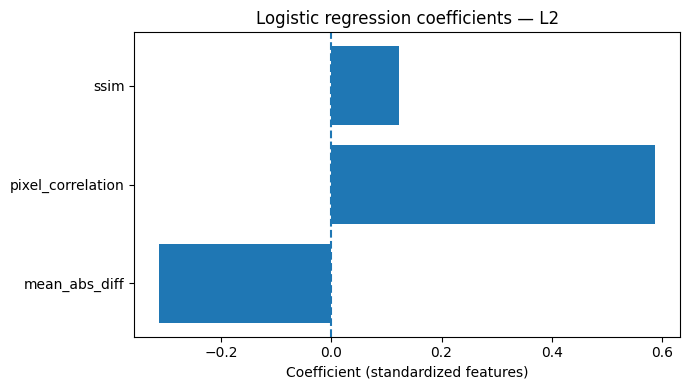

In [19]:
# Cell 14: Inspect standardized logistic regression coefficients

classifier = best_model.named_steps["classifier"]

coefficient_table = pd.DataFrame({
    "feature": FEATURES,
    "standardized_coefficient": classifier.coef_[0],
})

coefficient_table["absolute_magnitude"] = (
    coefficient_table["standardized_coefficient"].abs()
)

display(
    coefficient_table.sort_values(
        "absolute_magnitude",
        ascending=False
    )
)

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.barh(
    coefficient_table["feature"],
    coefficient_table["standardized_coefficient"]
)
plt.axvline(0, linestyle="--")
plt.xlabel("Coefficient (standardized features)")
plt.title(f"Logistic regression coefficients — {best_key[0].upper()}")
plt.tight_layout()
plt.show()

**Plot ROC and precision-recall curves**

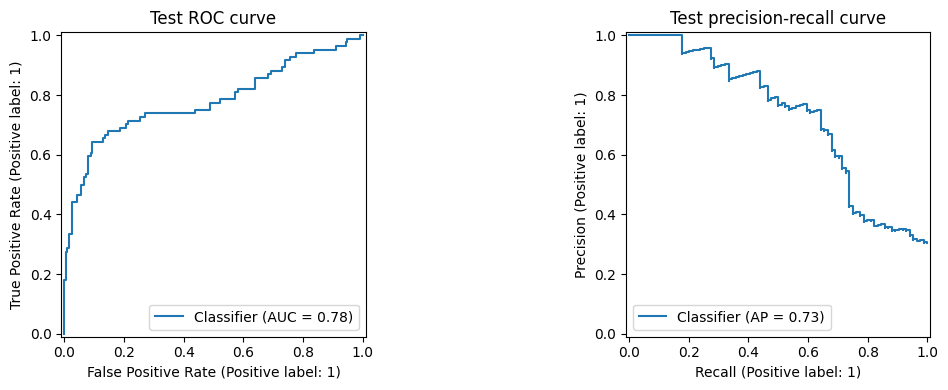

Test average precision: 0.7252304976458852


In [20]:
# Cell 15: Diagnostic curves on the held-out test predictions

from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay,
    average_precision_score,
)

if len(np.unique(y_test)) == 2:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    RocCurveDisplay.from_predictions(
        y_test, test_prob, ax=axes[0]
    )
    axes[0].set_title("Test ROC curve")

    PrecisionRecallDisplay.from_predictions(
        y_test, test_prob, ax=axes[1]
    )
    axes[1].set_title("Test precision-recall curve")

    plt.tight_layout()
    plt.show()

    print(
        "Test average precision:",
        average_precision_score(y_test, test_prob)
    )
else:
    print("Curves require both genuine and impostor pairs in the test set.")

**Identify false accepts and false rejects**

In [21]:
# Cell 16: Save examples for qualitative error analysis

error_cases = test_df.copy()
error_cases["predicted_probability_genuine"] = test_prob
error_cases["predicted_label"] = test_pred

error_cases["error_type"] = np.select(
    [
        (error_cases["label"] == 0) &
        (error_cases["predicted_label"] == 1),

        (error_cases["label"] == 1) &
        (error_cases["predicted_label"] == 0),
    ],
    [
        "False accept",
        "False reject",
    ],
    default="Correct prediction",
)

errors_only = error_cases[
    error_cases["error_type"] != "Correct prediction"
].copy()

print("Error counts:")
display(errors_only["error_type"].value_counts().to_frame("count"))

errors_only.to_csv(
    OUTPUT_DIR / "error_cases.csv",
    index=False
)

display(
    errors_only[
        [
            "image_a",
            "image_b",
            "identity_a",
            "identity_b",
            "label",
            "predicted_probability_genuine",
            "error_type",
        ]
    ].head(20)
)

Error counts:


,count
error_type,
False accept,112
False reject,16


,image_a,image_b,identity_a,identity_b,label,predicted_probability_genuine,error_type
59,/content/fingerprint_data/DB2_B (1)/108_1.tif,/content/fingerprint_data/DB2_B (1)/108_5.tif,DB2_B (1)::108,DB2_B (1)::108,1,0.413889,False reject
60,/content/fingerprint_data/DB2_B (1)/108_1.tif,/content/fingerprint_data/DB2_B (1)/108_6.tif,DB2_B (1)::108,DB2_B (1)::108,1,0.440588,False reject
62,/content/fingerprint_data/DB2_B (1)/108_1.tif,/content/fingerprint_data/DB2_B (1)/108_8.tif,DB2_B (1)::108,DB2_B (1)::108,1,0.285434,False reject
64,/content/fingerprint_data/DB2_B (1)/108_2.tif,/content/fingerprint_data/DB2_B (1)/108_4.tif,DB2_B (1)::108,DB2_B (1)::108,1,0.444324,False reject
67,/content/fingerprint_data/DB2_B (1)/108_2.tif,/content/fingerprint_data/DB2_B (1)/108_7.tif,DB2_B (1)::108,DB2_B (1)::108,1,0.465368,False reject
70,/content/fingerprint_data/DB2_B (1)/108_3.tif,/content/fingerprint_data/DB2_B (1)/108_5.tif,DB2_B (1)::108,DB2_B (1)::108,1,0.358150,False reject
71,/content/fingerprint_data/DB2_B (1)/108_3.tif,/content/fingerprint_data/DB2_B (1)/108_6.tif,DB2_B (1)::108,DB2_B (1)::108,1,0.309064,False reject
73,/content/fingerprint_data/DB2_B (1)/108_3.tif,/content/fingerprint_data/DB2_B (1)/108_8.tif,DB2_B (1)::108,DB2_B (1)::108,1,0.410248,False reject
74,/content/fingerprint_data/DB2_B (1)/108_4.tif,/content/fingerprint_data/DB2_B (1)/108_5.tif,DB2_B (1)::108,DB2_B (1)::108,1,0.293953,False reject
75,/content/fingerprint_data/DB2_B (1)/108_4.tif,/content/fingerprint_data/DB2_B (1)/108_6.tif,DB2_B (1)::108,DB2_B (1)::108,1,0.425606,False reject


**Create a model comparison table**

In [22]:
# Cell 17: Save the tuning table and a transparent comparison

from sklearn.metrics import accuracy_score, balanced_accuracy_score

baseline_acc = accuracy_score(y_test, baseline_predictions)
baseline_bal_acc = balanced_accuracy_score(
    y_test, baseline_predictions
)

comparison = pd.DataFrame([
    {
        "model": "Majority-class baseline",
        "validation_roc_auc": np.nan,
        "test_accuracy": baseline_acc,
        "test_balanced_accuracy": baseline_bal_acc,
        "test_roc_auc": np.nan,
    },
    {
        "model": f"Logistic regression ({best_key[0]}, C={best_key[1]})",
        "validation_roc_auc": best_row["validation_roc_auc"],
        "test_accuracy": accuracy_score(y_test, test_pred),
        "test_balanced_accuracy": balanced_accuracy_score(
            y_test, test_pred
        ),
        "test_roc_auc": test_auc,
    },
])

display(comparison)

tuning_results.to_csv(
    OUTPUT_DIR / "validation_tuning_results.csv",
    index=False
)

comparison.to_csv(
    OUTPUT_DIR / "model_comparison.csv",
    index=False
)

print("Comparison saved in:", OUTPUT_DIR)

,model,validation_roc_auc,test_accuracy,test_balanced_accuracy,test_roc_auc
0,Majority-class baseline,NaN,0.695652,0.500000,NaN
1,"Logistic regression (l2, C=0.01)",0.617932,0.536232,0.613095,0.78032


Comparison saved in: /content/ds_a3_results


**Record reproducibility information**

In [23]:
# Cell 18: Save versions and experiment configuration

import sys
import platform
import json
import numpy
import pandas
import sklearn
import PIL
import skimage

environment = {
    "python": sys.version,
    "platform": platform.platform(),
    "numpy": numpy.__version__,
    "pandas": pandas.__version__,
    "scikit_learn": sklearn.__version__,
    "pillow": PIL.__version__,
    "scikit_image": skimage.__version__,
}

configuration = {
    "random_seed": 42,
    "image_size": list(IMAGE_SIZE),
    "features": FEATURES,
    "selected_penalty": best_key[0],
    "selected_C": best_key[1],
    "threshold": 0.5,
    "split_strategy": "identity-level",
}

(OUTPUT_DIR / "environment.json").write_text(
    json.dumps(environment, indent=2)
)

(OUTPUT_DIR / "experiment_config.json").write_text(
    json.dumps(configuration, indent=2)
)

print(json.dumps(environment, indent=2))
print("\nSaved environment and configuration.")

{
  "python": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "scikit_learn": "1.6.1",
  "pillow": "11.3.0",
  "scikit_image": "0.25.2"
}

Saved environment and configuration.


#**diagnostics and final deliverables**

**Run a learning curve**

,fraction,training_identities,training_pairs,training_auc,validation_auc
0,0.4,6,1128,0.800577,0.633681
1,0.6,9,2556,0.728726,0.623016
2,0.8,12,4560,0.727478,0.615451
3,1.0,14,6216,0.735683,0.617932


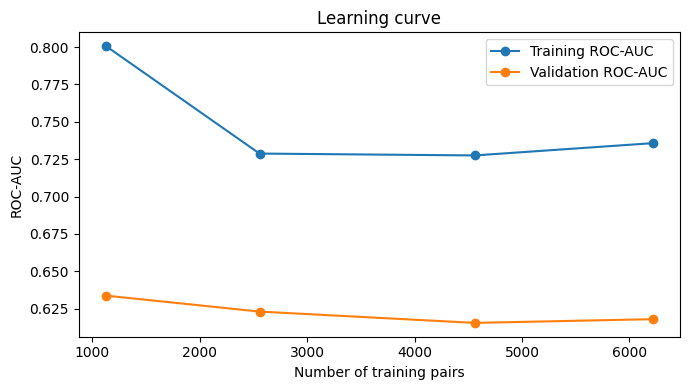

In [24]:
# Cell 19: Learning curve using identity-disjoint partitions

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.metrics import roc_auc_score

train_df = feature_sets["train"]
val_df = feature_sets["validation"]

X_train = train_df[FEATURES].to_numpy()
y_train = train_df["label"].to_numpy()

X_val = val_df[FEATURES].to_numpy()
y_val = val_df["label"].to_numpy()

if len(np.unique(y_val)) != 2:
    raise ValueError(
        "Validation data must contain both classes for ROC-AUC."
    )

# Identity-level subsampling helps avoid mixing identities.
train_identity_groups = sorted(
    train_df["identity_a"].unique()
)

fractions = [0.4, 0.6, 0.8, 1.0]
learning_results = []

for fraction in fractions:
    n_ids = max(
        2,
        int(np.ceil(fraction * len(train_identity_groups)))
    )
    selected_ids = set(train_identity_groups[:n_ids])

    mask = (
        train_df["identity_a"].isin(selected_ids)
        & train_df["identity_b"].isin(selected_ids)
    )

    X_sub = train_df.loc[mask, FEATURES].to_numpy()
    y_sub = train_df.loc[mask, "label"].to_numpy()

    if len(np.unique(y_sub)) < 2:
        continue

    model = clone(best_model)
    model.fit(X_sub, y_sub)

    train_auc = roc_auc_score(
        y_sub, model.predict_proba(X_sub)[:, 1]
    )
    val_auc = roc_auc_score(
        y_val, model.predict_proba(X_val)[:, 1]
    )

    learning_results.append({
        "fraction": fraction,
        "training_identities": n_ids,
        "training_pairs": len(y_sub),
        "training_auc": train_auc,
        "validation_auc": val_auc,
    })

learning_df = pd.DataFrame(learning_results)
display(learning_df)

if not learning_df.empty:
    plt.figure(figsize=(7, 4))
    plt.plot(
        learning_df["training_pairs"],
        learning_df["training_auc"],
        marker="o",
        label="Training ROC-AUC",
    )
    plt.plot(
        learning_df["training_pairs"],
        learning_df["validation_auc"],
        marker="o",
        label="Validation ROC-AUC",
    )
    plt.xlabel("Number of training pairs")
    plt.ylabel("ROC-AUC")
    plt.title("Learning curve")
    plt.legend()
    plt.tight_layout()
    plt.show()

    learning_df.to_csv(
        OUTPUT_DIR / "learning_curve.csv",
        index=False
    )

# AI Use Log-DS-A3

## Tool
ChatGPT

## Tasks assisted
- Planning the notebook structure
- Understanding identity-level data splitting
- Drafting code for feature extraction and evaluation
- Explaining classification metrics and limitations

## Verification
- Document the notebook cells actually executed.
- Record checks performed and results observed.
- Note errors, corrections, and independently verified outputs.

## Accepted advice
Record the suggestions actually used.

## Rejected or modified advice
Record suggestions rejected or modified and explain why.

## Limitations
Disclose any unverified code and limitations of the experiment. Do not report fabricated results.

In [27]:
import sys
print("Python:", sys.version)

packages = [
    "numpy",
    "pandas",
    "scikit-learn",
    "scikit-image",
    "Pillow",
    "matplotlib",
    "seaborn",
]

for package in packages:
    try:
        module = __import__(
            package.replace("-", "_").replace("Pillow", "PIL")
        )
        print(package, getattr(module, "__version__", "version unavailable"))
    except Exception as exc:
        print(package, "not available:", exc)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
numpy 2.1.3
pandas 2.2.3
scikit-learn not available: No module named 'scikit_learn'
scikit-image not available: No module named 'scikit_image'
Pillow 11.3.0
matplotlib 3.10.0
seaborn 0.13.2
